<a href="https://colab.research.google.com/github/tiendrebeogoarlette97-bit/NLP-BERT-Sentiment-Classification/blob/main/notebooks/NLP_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification de sentiments : TF-IDF et BERT

**Objectif :** comparer une baseline TF-IDF + régression logistique à BERT-base-uncased fine-tuné sur SST-2 (GLUE). Les modèles seront évalués sur la même partition officielle de validation, avec accuracy, F1 et matrices de confusion. Les labels du test officiel ne sont pas publics. Aucune performance n'est présupposée.

## 1. Installation et configuration

Activer un GPU dans Colab : Exécution > Modifier le type d'exécution > T4 GPU. La seed fixe les générateurs aléatoires, sans garantir une reproductibilité bit à bit sur GPU.

In [ ]:
%pip install -q transformers==5.24.1 datasets==5.0.1 accelerate==1.16.0 pyarrow==23.0.1 jedi

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from transformers import set_seed
from IPython.display import display

SEED = 42
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch :', torch.__version__)
print('Device :', DEVICE)
if torch.cuda.is_available():
    print('GPU :', torch.cuda.get_device_name(0))
else:
    print('Attention : activer un GPU avant le fine-tuning.')

## 2. Chargement de SST-2

Nous conservons les partitions officielles. Le train sert à apprendre les paramètres et le vocabulaire TF-IDF ; la validation sert à comparer les modèles. Le test est inspecté uniquement pour sa structure.

In [ ]:
dataset = load_dataset('nyu-mll/glue', 'sst2')
print(dataset)
train_df = dataset['train'].to_pandas()
val_df = dataset['validation'].to_pandas()
test_df = dataset['test'].to_pandas()
label_names = {0: 'Negative', 1: 'Positive'}
display(train_df.head(10))
print('Labels du test :', test_df['label'].unique())

## 3. Analyse exploratoire des données

Nous vérifions la qualité des textes, les labels, les doublons et les longueurs. Les doublons sont recensés sans suppression automatique afin de préserver le protocole officiel ; les éventuels chevauchements train/validation seront signalés comme limite.

In [ ]:
summary = []
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    normalized = df['sentence'].fillna('').str.strip().str.lower()
    summary.append({'split': name, 'rows': len(df), 'missing_text': df['sentence'].isna().sum(), 'empty_text': normalized.eq('').sum(), 'duplicate_texts': normalized.duplicated().sum(), 'label_values': sorted(df['label'].unique().tolist())})
display(pd.DataFrame(summary))
assert train_df['label'].isin([0, 1]).all()
assert val_df['label'].isin([0, 1]).all()
train_texts = set(train_df['sentence'].str.strip().str.lower())
val_texts = set(val_df['sentence'].str.strip().str.lower())
print('Textes distincts communs train/validation :', len(train_texts & val_texts))

In [ ]:
eda = pd.concat([train_df.assign(split='train'), val_df.assign(split='validation')], ignore_index=True)
eda['sentiment'] = eda['label'].map(label_names)
eda['word_count'] = eda['sentence'].str.split().str.len()
counts = pd.crosstab(eda['split'], eda['sentiment'])
display(counts)
display(pd.crosstab(eda['split'], eda['sentiment'], normalize='index').mul(100).round(2))
display(eda.groupby('split')['word_count'].describe(percentiles=[.5, .9, .95, .99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ['train', 'validation']):
    sns.countplot(data=eda[eda['split'] == split], x='sentiment', order=['Negative', 'Positive'], ax=ax)
    ax.set_title(f'Distribution des classes — {split}')
    ax.set_xlabel('Sentiment')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.histplot(data=eda, x='word_count', hue='split', stat='density', common_norm=False, element='step', bins=40)
plt.xlabel('Nombre de mots par phrase')
plt.title('Distribution des longueurs de phrases')
plt.tight_layout()
plt.show()

### Interprétation de l'EDA

Résultats observés dans Colab : 67 349 exemples train, 872 validation et 1 821 test. Aucun texte manquant ou vide. Le train contient 371 occurrences redondantes après normalisation (environ 0,55 %), contre aucune en validation et test. Aucun chevauchement textuel exact normalisé train/validation n'a été détecté ; cela n'exclut pas les quasi-doublons. Les classes positives représentent 55,78 % du train et 50,92 % de la validation. Nous conservons les partitions officielles sans rééquilibrage. Les textes de validation sont plus longs (19,55 mots en moyenne contre 9,41), ce qui motive une analyse ultérieure des performances par longueur. Les labels test (-1) ne sont pas publics. Les résultats rapportés concernent la validation officielle.

In [ ]:
duplicate_check = train_df.assign(normalized=train_df['sentence'].str.strip().str.lower()).groupby('normalized')['label'].agg(['size', 'nunique'])
print('Groupes de textes répétés :', int((duplicate_check['size'] > 1).sum()))
print('Groupes avec labels contradictoires :', int((duplicate_check['nunique'] > 1).sum()))

## 4. Baseline finale : TF-IDF + régression logistique L2

Nous retenons C=5, selon la règle prédéfinie d'une erreur standard puis de minimisation du gap. F1 macro structurel : 0,8101 ; gap : 0,1676. Le surapprentissage reste une limite. Les recherches coûteuses sont archivées dans `notebooks/experiments_baseline.ipynb`. La validation officielle n'a pas servi directement à sélectionner C=5 mais a déjà été consultée pour les modèles précédents. Le pipeline est ajusté uniquement sur le train officiel.

In [ ]:
from time import perf_counter
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay, log_loss
from sklearn.dummy import DummyClassifier

X_train = train_df['sentence'].tolist()
y_train = train_df['label'].to_numpy()
X_val = val_df['sentence'].tolist()
y_val = val_df['label'].to_numpy()

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, norm='l2', token_pattern=r'(?u)\b\w+\b')),
    ('lr', LogisticRegression(C=5.0, solver='lbfgs', max_iter=1000, random_state=SEED))
])
t0 = perf_counter()
baseline.fit(X_train, y_train)
baseline_train_time = perf_counter() - t0
t0 = perf_counter()
baseline_proba = baseline.predict_proba(X_val)
baseline_pred = baseline.classes_[baseline_proba.argmax(axis=1)]
baseline_inference_time = perf_counter() - t0
print('Taille du vocabulaire :', len(baseline.named_steps['tfidf'].vocabulary_))
print('Iterations LR :', baseline.named_steps['lr'].n_iter_)
print('Temps entrainement (s) :', round(baseline_train_time, 3))

In [ ]:
def classification_metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred, zero_division=0), 'recall': recall_score(y_true, y_pred, zero_division=0), 'f1': f1_score(y_true, y_pred, zero_division=0), 'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)}

baseline_metrics = classification_metrics(y_val, baseline_pred)
baseline_metrics.update({'train_time_s': baseline_train_time, 'inference_time_s': baseline_inference_time, 'validation_log_loss': log_loss(y_val, baseline_proba, labels=[0,1])})
results = pd.DataFrame([{'model': 'TF-IDF + LR', **baseline_metrics}])
display(results.round(4))
print(classification_report(y_val, baseline_pred, target_names=['Negative', 'Positive'], digits=4))
print('Accuracy train :', accuracy_score(y_train, baseline.predict(X_train)))
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_train), 1)), y_train)
print('Accuracy classe majoritaire :', dummy.score(np.zeros((len(y_val), 1)), y_val))
ConfusionMatrixDisplay.from_predictions(y_val, baseline_pred, display_labels=['Negative', 'Positive'], cmap='Blues')
plt.title('Matrice de confusion — TF-IDF + LR')
plt.tight_layout()
plt.show()

### Interprétabilité de la baseline

Les coefficients positifs et négatifs sont des associations apprises avec la classe positive et négative respectivement. Ils ne prouvent pas une relation causale.

In [ ]:
features = np.array(baseline.named_steps['tfidf'].get_feature_names_out())
weights = baseline.named_steps['lr'].coef_[0]
order = np.argsort(weights)
selected = np.r_[order[:15], order[-15:]]
coef_df = pd.DataFrame({'term': features[selected], 'coefficient': weights[selected]}).sort_values('coefficient')
plt.figure(figsize=(9, 10))
plt.barh(coef_df['term'], coef_df['coefficient'], color=np.where(coef_df['coefficient'] > 0, 'seagreen', 'indianred'))
plt.axvline(0, color='black', linewidth=.8)
plt.title('Termes les plus associés aux sentiments — régression logistique')
plt.xlabel('Coefficient appris')
plt.tight_layout()
plt.show()
val_predictions = val_df[['idx', 'sentence', 'label']].copy()
val_predictions['baseline_pred'] = baseline_pred
val_predictions['baseline_prob_positive'] = baseline_proba[:, 1]
display(val_predictions[val_predictions['label'] != val_predictions['baseline_pred']].head(10))

In [ ]:
train_f1_macro = f1_score(y_train, baseline.predict(X_train), average='macro')
print('F1 macro train :', train_f1_macro)
print('Gap F1 macro :', train_f1_macro - baseline_metrics['f1_macro'])
print('Coefficients non nuls :', np.count_nonzero(baseline.named_steps['lr'].coef_))

### Résultats observés de la baseline finale

Sur la validation officielle : 717 prédictions correctes sur 872 (accuracy 82,22 %), F1 macro 82,15 %, 98 faux positifs et 57 faux négatifs. F1 macro train 97,79 %, gap 15,64 points. Accuracy par longueur : 86,84 % (1–10 mots), 84,12 % (11–20), 78,68 % (21+). Le surapprentissage et les difficultés contextuelles restent des limites. Nous comparerons BERT sur les mêmes observations, sans supposer qu'il résout automatiquement ces problèmes.

## 5. Analyse par longueur et sauvegarde

In [ ]:
val_predictions['word_count'] = val_predictions['sentence'].str.split().str.len()
val_predictions['length_group'] = pd.cut(val_predictions['word_count'], bins=[0,10,20,np.inf], labels=['1-10','11-20','21+'])
length_results = pd.DataFrame([{'length_group':str(g), 'n':len(frame), 'accuracy':accuracy_score(frame['label'],frame['baseline_pred']), 'f1_macro':f1_score(frame['label'],frame['baseline_pred'],labels=[0,1],average='macro',zero_division=0)} for g,frame in val_predictions.groupby('length_group',observed=True)])
display(length_results.round(4))

In [ ]:
import json, shutil, joblib
from pathlib import Path
out = Path('baseline_artifacts'); out.mkdir(exist_ok=True)
results.to_csv(out/'metrics.csv', index=False)
val_predictions.to_csv(out/'predictions.csv', index=False)
length_results.to_csv(out/'length_results.csv',index=False)
joblib.dump(baseline, out/'baseline_l2_c5.joblib')
(out/'config.json').write_text(json.dumps({'model':'TF-IDF + LR L2','C':5,'seed':42,'ngram_range':[1,2],'min_df':2,'train_f1_macro':float(train_f1_macro)},indent=2))
shutil.make_archive('baseline_artifacts','zip',out)
print('Archive créée : baseline_artifacts.zip')

In [ ]:
from google.colab import files
files.download('baseline_artifacts.zip')

## 6. Tokenisation BERT

Nous chargeons le tokenizer du checkpoint bert-base-uncased, sans appliquer le prétraitement TF-IDF. Nous inspectons WordPiece, les identifiants, les tokens spéciaux et les masques. Les longueurs incluent les tokens spéciaux ; la limite de 128 tokens est un choix initial, dont nous mesurons le taux de troncature avant entraînement.

Mesures déjà observées : maximum 66 tokens en train, 55 en validation ; aucune troncature à 128.

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding
MODEL_NAME = 'bert-base-uncased'
MAX_LENGTH = 128
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
example = 'This movie was not good, but the cinematography was unforgettable.'
encoded = tokenizer(example, padding='max_length', max_length=32, truncation=True, return_attention_mask=True)
display(pd.DataFrame({'token': tokenizer.convert_ids_to_tokens(encoded['input_ids']), 'input_id': encoded['input_ids'], 'attention_mask': encoded['attention_mask']}))
print('Taille du vocabulaire du tokenizer :', len(tokenizer))

In [ ]:
token_length_rows = []
for split in ['train', 'validation']:
    lengths = []
    for batch in dataset[split].iter(batch_size=512):
        ids = tokenizer(batch['sentence'], add_special_tokens=True, truncation=False, verbose=False)['input_ids']
        lengths.extend(map(len, ids))
    lengths = np.asarray(lengths)
    token_length_rows.append({'split':split,'n':len(lengths),'mean':lengths.mean(),'median':np.median(lengths),'p95':np.percentile(lengths,95),'p99':np.percentile(lengths,99),'max':lengths.max(),'truncated_at_128':int((lengths>MAX_LENGTH).sum()),'truncation_rate':float((lengths>MAX_LENGTH).mean())})
display(pd.DataFrame(token_length_rows).round(4))

In [ ]:
def tokenize_batch(batch):
    return tokenizer(batch['sentence'], truncation=True, max_length=MAX_LENGTH)

tokenized = dataset.map(tokenize_batch, batched=True, remove_columns=['sentence','idx'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8 if torch.cuda.is_available() else None)
example_batch = data_collator([tokenized['train'][i] for i in range(4)])
print(tokenized)
print({key:tuple(value.shape) for key,value in example_batch.items()})
print('Labels du batch :', example_batch['labels'].tolist())

Le padding dynamique complète uniquement jusqu'à la longueur maximale du lot (arrondie au multiple de 8 sur GPU), ce qui réduit le calcul inutile. Le jeu test non étiqueté ne sera pas utilisé pour calculer les performances. Les sorties observées confirment que la tokenisation est opérationnelle.

## 7. Fine-tuning de BERT

Nous utilisons `bert-base-uncased` avec une tête de classification binaire initialisée pour cette tâche. Toutes les couches sont entraînables. Les paramètres demandés sont deux époques et un learning rate de 2e-5. Choix complémentaires : batch train 32, batch évaluation 64, AdamW, weight decay 0,01, warmup 6 %, précision mixte FP16 sur T4, seed 42. Le padding dynamique préserve les textes (aucune troncature observée à 128). Nous évaluons après chaque époque, mais conservons le modèle de la deuxième époque conformément au protocole fixé. La validation officielle est un benchmark de comparaison et non un test aveugle indépendant. Les checkpoints locaux ne survivent pas à la suppression du runtime. Ne pas lancer deux entraînements en parallèle.

In [ ]:
# Reprise autonome du fine-tuning après changement de runtime
import json, shutil, inspect, gc
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments, set_seed
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

assert torch.cuda.is_available(), "Activer un GPU dans Runtime > Change runtime type avant le fine-tuning."
SEED = 42
MODEL_NAME = 'bert-base-uncased'
MAX_LENGTH = 128
set_seed(SEED)
if 'dataset' not in globals():
    dataset = load_dataset('nyu-mll/glue','sst2')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
def tokenize_batch(batch):
    return tokenizer(batch['sentence'], truncation=True, max_length=MAX_LENGTH)
if 'tokenized' not in globals():
    tokenized = dataset.map(tokenize_batch, batched=True, remove_columns=['sentence','idx'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
print('GPU :', torch.cuda.get_device_name(0))
print('Train / validation :', len(tokenized['train']),len(tokenized['validation']))

In [ ]:
def bert_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    pred = np.argmax(logits, axis=-1)
    return {'accuracy':accuracy_score(labels,pred),
            'precision':precision_score(labels,pred,zero_division=0),
            'recall':recall_score(labels,pred,zero_division=0),
            'f1':f1_score(labels,pred,zero_division=0),
            'f1_macro':f1_score(labels,pred,average='macro',zero_division=0)}

set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0:'Negative',1:'Positive'},
    label2id={'Negative':0,'Positive':1}
)
print('Paramètres totaux :', sum(p.numel() for p in model.parameters()))
print('Paramètres entraînables :', sum(p.numel() for p in model.parameters() if p.requires_grad))
args_kwargs = dict(output_dir='bert_checkpoints', num_train_epochs=2,
    learning_rate=2e-5, per_device_train_batch_size=32,
    per_device_eval_batch_size=64, weight_decay=0.01,
    optim='adamw_torch', fp16=True,
    logging_steps=100, save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=False, seed=SEED, report_to='none')
arg_params=inspect.signature(TrainingArguments.__init__).parameters
import math
# Warmup: 6% of optimizer steps for this single-GPU run.
effective_batch = args_kwargs['per_device_train_batch_size'] * args_kwargs.get('gradient_accumulation_steps', 1)
total_steps = math.ceil(len(tokenized['train']) / effective_batch) * int(args_kwargs['num_train_epochs'])
args_kwargs['warmup_steps'] = math.ceil(0.06 * total_steps)
print('Total optimizer steps (estimated):', total_steps)
print('Warmup steps:', args_kwargs['warmup_steps'])
unsupported = set(args_kwargs) - set(arg_params)
if unsupported:
    raise TypeError(f"Unsupported TrainingArguments in installed version: {sorted(unsupported)}")
args_kwargs['eval_strategy' if 'eval_strategy' in arg_params else 'evaluation_strategy']='epoch'
training_args=TrainingArguments(**args_kwargs)
trainer_kwargs=dict(model=model,args=training_args,train_dataset=tokenized['train'],
    eval_dataset=tokenized['validation'],data_collator=data_collator,compute_metrics=bert_metrics)
trainer_params=inspect.signature(Trainer.__init__).parameters
trainer_kwargs['processing_class' if 'processing_class' in trainer_params else 'tokenizer']=tokenizer
trainer=Trainer(**trainer_kwargs)
print('Configuration validée. Le modèle sera entraîné sur toutes les données train.')

### Lancer l'entraînement

Le warning concernant les poids de la couche classifier nouvellement initialisés est attendu pour un checkpoint BERT non spécialisé. En cas de CUDA out of memory, redémarrer la session, relancer les cellules de reprise et de configuration, puis utiliser batch train 16 et gradient_accumulation_steps=2 (batch effectif 32). Ne modifier ni les deux époques ni le learning rate.

In [ ]:
t0=perf_counter()
train_output=trainer.train()
bert_train_seconds=perf_counter()-t0
print('Temps total entraînement avec évaluations et checkpoints (s) :',bert_train_seconds)
trainer.save_model('bert_final_model')
tokenizer.save_pretrained('bert_final_model')

## 8. Évaluation du BERT fine-tuné

Le modèle final est celui de la deuxième époque. Les métriques de validation et le train complet sont évalués en mode inférence (dropout désactivé), pour rendre le gap F1 macro comparable à celui de la régression logistique. Les temps mesurés sur CPU et GPU sont descriptifs, pas une comparaison matérielle contrôlée.

In [ ]:
history=pd.DataFrame(trainer.state.log_history)
display(history.tail(12))
t0=perf_counter()
torch.cuda.synchronize()
bert_output=trainer.predict(tokenized['validation'])
torch.cuda.synchronize()
bert_inference_seconds=perf_counter()-t0
bert_logits=bert_output.predictions
if isinstance(bert_logits,tuple):
    bert_logits=bert_logits[0]
bert_pred=np.argmax(bert_logits,axis=-1)
bert_probs=torch.softmax(torch.tensor(bert_logits).float(),dim=-1).numpy()
bert_train_eval=trainer.evaluate(eval_dataset=tokenized['train'],metric_key_prefix='train_eval')
bert_final_metrics={k.removeprefix('test_'):v for k,v in bert_output.metrics.items() if k in ['test_accuracy','test_precision','test_recall','test_f1','test_f1_macro','test_loss']}
bert_final_metrics['train_f1_macro']=bert_train_eval['train_eval_f1_macro']
bert_final_metrics['train_accuracy']=bert_train_eval['train_eval_accuracy']
bert_final_metrics['gap_f1_macro']=bert_final_metrics['train_f1_macro']-bert_final_metrics['f1_macro']
bert_final_metrics['train_time_s']=bert_train_seconds
bert_final_metrics['inference_time_s']=bert_inference_seconds
display(pd.DataFrame([{'model':'BERT fine-tuned',**bert_final_metrics}]).round(4))
print(classification_report(bert_output.label_ids,bert_pred,target_names=['Negative','Positive'],digits=4))
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(bert_output.label_ids,bert_pred,labels=[0,1],display_labels=['Negative','Positive'],cmap='Blues',ax=ax)
ax.set_title('BERT fine-tuned — SST-2 validation')
plt.tight_layout();plt.show()

In [ ]:
# Les pertes train sont des moyennes de fenêtres de logging ;
# les pertes validation correspondent à des évaluations à la fin de chaque époque.
fig,axes=plt.subplots(1,2,figsize=(12,4))
if 'loss' in history:
    h=history.dropna(subset=['loss'])
    axes[0].plot(h['epoch'],h['loss'],label='Train loss (fenêtres)')
if 'eval_loss' in history:
    h=history.dropna(subset=['eval_loss'])
    axes[0].plot(h['epoch'],h['eval_loss'],'o-',label='Validation loss')
    for key in ['eval_accuracy','eval_f1_macro']:
        if key in h: axes[1].plot(h['epoch'],h[key],'o-',label=key)
axes[0].set_ylabel('Loss');axes[1].set_ylabel('Score')
for ax in axes:
    ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()

### Sauvegarde des résultats avant toute nouvelle session

L'archive suivante contient les métriques, prédictions et historique d'entraînement ; les poids du modèle restent dans `bert_final_model`. Conserver aussi ce dossier séparément si l'on souhaite éviter un nouvel entraînement. Ne pas enregistrer les checkpoints volumineux dans GitHub.

In [ ]:
bert_dir=Path('bert_artifacts');bert_dir.mkdir(exist_ok=True)
pd.DataFrame([{'model':'BERT fine-tuned',**bert_final_metrics}]).to_csv(bert_dir/'metrics.csv',index=False)
bert_predictions=dataset['validation'].to_pandas()[['idx','sentence','label']].copy()
assert np.array_equal(bert_predictions.label.to_numpy(),bert_output.label_ids)
bert_predictions['bert_pred']=bert_pred
bert_predictions['bert_prob_positive']=bert_probs[:,1]
bert_predictions.to_csv(bert_dir/'predictions.csv',index=False)
history.to_csv(bert_dir/'training_history.csv',index=False)
trainer.state.save_to_json(str(bert_dir/'trainer_state.json'))
shutil.make_archive('bert_artifacts','zip',bert_dir)
print('Archive créée : bert_artifacts.zip')
from google.colab import files
files.download('bert_artifacts.zip')

### Résultats observés du fine-tuning complet

Époque 1 : accuracy 0,930046, F1 macro 0,930035, loss validation 0,217088. Époque 2 : accuracy 0,928899, F1 macro 0,928862, loss validation 0,236187. Le modèle de la deuxième époque est conservé selon le protocole fixé. Matrice [[395,33],[29,415]], 810 prédictions correctes, 62 erreurs. F1 macro train 0,980996 et gap 0,0521. Temps total 556,389 s. Les dernières fenêtres de loss train diminuent tandis que la loss validation augmente : signe compatible avec un début de surapprentissage, sans preuve d'un phénomène important à partir de deux époques. L'accuracy baisse d'une seule observation entre les deux époques. L'objectif d'environ 92 % est atteint.

## 9. Bonus : Frozen BERT

Pour isoler l'effet de l'adaptation des paramètres de l'encodeur, nous repartons du checkpoint préentraîné original, et non de BERT déjà fine-tuné. Nous gelons `model.bert` et entraînons uniquement la couche classifier. Même dataset, mêmes deux époques, batch, learning rate et seed que le fine-tuning complet : comparaison à hyperparamètres contrôlés, pas optimisation spécifique de Frozen BERT. Le dropout de l'encodeur reste actif en mode train avec Trainer ; ses poids restent gelés. Le score peut être inférieur et ne doit pas être artificiellement amélioré. Avant cette section, télécharger les archives baseline et BERT ; conserver les poids du modèle complet séparément si nécessaire.

In [ ]:
# Reprise autonome pour Frozen BERT
# Libérer le Trainer et modèle précédents si présents, sans supprimer les fichiers.
for key in ['trainer','model','trainer_kwargs','train_output']:
    globals().pop(key,None)
import gc, torch
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
import json, shutil, inspect, gc
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments, set_seed
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

assert torch.cuda.is_available(), "Activer un GPU dans Runtime > Change runtime type avant le fine-tuning."
SEED = 42
MODEL_NAME = 'bert-base-uncased'
MAX_LENGTH = 128
set_seed(SEED)
if 'dataset' not in globals():
    dataset = load_dataset('nyu-mll/glue','sst2')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
def tokenize_batch(batch):
    return tokenizer(batch['sentence'], truncation=True, max_length=MAX_LENGTH)
if 'tokenized' not in globals():
    tokenized = dataset.map(tokenize_batch, batched=True, remove_columns=['sentence','idx'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
print('GPU :', torch.cuda.get_device_name(0))
print('Train / validation :', len(tokenized['train']),len(tokenized['validation']))

In [ ]:
def bert_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    pred = np.argmax(logits, axis=-1)
    return {'accuracy':accuracy_score(labels,pred),
            'precision':precision_score(labels,pred,zero_division=0),
            'recall':recall_score(labels,pred,zero_division=0),
            'f1':f1_score(labels,pred,zero_division=0),
            'f1_macro':f1_score(labels,pred,average='macro',zero_division=0)}

set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0:'Negative',1:'Positive'},
    label2id={'Negative':0,'Positive':1}
)
for param in model.bert.parameters():
    param.requires_grad = False
assert all(not param.requires_grad for param in model.bert.parameters())
assert all(param.requires_grad for param in model.classifier.parameters())
print('Paramètres totaux :', sum(p.numel() for p in model.parameters()))
print('Paramètres entraînables :', sum(p.numel() for p in model.parameters() if p.requires_grad))
args_kwargs = dict(output_dir='frozen_bert_checkpoints', num_train_epochs=2,
    learning_rate=2e-5, per_device_train_batch_size=32,
    per_device_eval_batch_size=64, weight_decay=0.01,
    optim='adamw_torch', fp16=True,
    logging_steps=100, save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=False, seed=SEED, report_to='none')
arg_params=inspect.signature(TrainingArguments.__init__).parameters
import math
# Warmup: 6% of optimizer steps for this single-GPU run.
effective_batch = args_kwargs['per_device_train_batch_size'] * args_kwargs.get('gradient_accumulation_steps', 1)
total_steps = math.ceil(len(tokenized['train']) / effective_batch) * int(args_kwargs['num_train_epochs'])
args_kwargs['warmup_steps'] = math.ceil(0.06 * total_steps)
print('Total optimizer steps (estimated):', total_steps)
print('Warmup steps:', args_kwargs['warmup_steps'])
unsupported = set(args_kwargs) - set(arg_params)
if unsupported:
    raise TypeError(f"Unsupported TrainingArguments in installed version: {sorted(unsupported)}")
args_kwargs['eval_strategy' if 'eval_strategy' in arg_params else 'evaluation_strategy']='epoch'
training_args=TrainingArguments(**args_kwargs)
trainer_kwargs=dict(model=model,args=training_args,train_dataset=tokenized['train'],
    eval_dataset=tokenized['validation'],data_collator=data_collator,compute_metrics=bert_metrics)
trainer_params=inspect.signature(Trainer.__init__).parameters
trainer_kwargs['processing_class' if 'processing_class' in trainer_params else 'tokenizer']=tokenizer
trainer=Trainer(**trainer_kwargs)
print('Configuration validée. Seule la tête de classification sera entraînée.')

In [ ]:
t0=perf_counter()
frozen_train_output=trainer.train()
frozen_train_seconds=perf_counter()-t0
trainer.save_model('frozen_bert_final_model')
tokenizer.save_pretrained('frozen_bert_final_model')

In [ ]:
frozen_history=pd.DataFrame(trainer.state.log_history)
torch.cuda.synchronize()
t0=perf_counter()
frozen_output=trainer.predict(tokenized['validation'])
torch.cuda.synchronize()
frozen_inference_seconds=perf_counter()-t0
logits=frozen_output.predictions
if isinstance(logits,tuple): logits=logits[0]
frozen_pred=np.argmax(logits,axis=-1)
frozen_probs=torch.softmax(torch.tensor(logits).float(),dim=-1).numpy()
frozen_train_eval=trainer.evaluate(eval_dataset=tokenized['train'],metric_key_prefix='train_eval')
frozen_metrics={k.removeprefix('test_'):v for k,v in frozen_output.metrics.items() if k in ['test_accuracy','test_precision','test_recall','test_f1','test_f1_macro','test_loss']}
frozen_metrics.update(train_f1_macro=frozen_train_eval['train_eval_f1_macro'],train_accuracy=frozen_train_eval['train_eval_accuracy'],train_time_s=frozen_train_seconds,inference_time_s=frozen_inference_seconds)
frozen_metrics['gap_f1_macro']=frozen_metrics['train_f1_macro']-frozen_metrics['f1_macro']
display(pd.DataFrame([{'model':'Frozen BERT',**frozen_metrics}]).round(4))
print(classification_report(frozen_output.label_ids,frozen_pred,target_names=['Negative','Positive'],digits=4))
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(frozen_output.label_ids,frozen_pred,labels=[0,1],display_labels=['Negative','Positive'],cmap='Blues',ax=ax)
ax.set_title('Frozen BERT — SST-2 validation')
plt.tight_layout();plt.show()
frozen_dir=Path('frozen_bert_artifacts');frozen_dir.mkdir(exist_ok=True)
pd.DataFrame([{'model':'Frozen BERT',**frozen_metrics}]).to_csv(frozen_dir/'metrics.csv',index=False)
predictions=dataset['validation'].to_pandas()[['idx','sentence','label']].copy()
assert np.array_equal(predictions.label.to_numpy(),frozen_output.label_ids)
predictions['frozen_pred']=frozen_pred
predictions['frozen_prob_positive']=frozen_probs[:,1]
predictions.to_csv(frozen_dir/'predictions.csv',index=False)
frozen_history.to_csv(frozen_dir/'training_history.csv',index=False)
fig.savefig(frozen_dir/'confusion_matrix.png',dpi=160)
shutil.make_archive('frozen_bert_artifacts','zip',frozen_dir)
from google.colab import files
files.download('frozen_bert_artifacts.zip')

### Résultats observés — Frozen BERT

Accuracy 0,552752, F1 macro 0,445155, F1 macro train 0,460066, gap 0,0149. Matrice [[49,379],[11,433]]. Le modèle prédit 812 positifs sur 872. Les faibles performances train et validation suggèrent un sous-apprentissage sous cette configuration. Le learning rate 2e-5 est identique au fine-tuning complet mais peut être trop faible pour une tête initialisée aléatoirement ; ce résultat ne représente pas le plafond de Frozen BERT. Le dropout reste actif durant l'entraînement. L'expérience est conservée comme bonus contrôlé, sans optimisation supplémentaire.

## 10. Comparaison finale et analyse des erreurs

Cette section peut être exécutée indépendamment des entraînements. Si les trois archives ne sont pas présentes, les téléverser depuis les fichiers téléchargés précédemment. Les prédictions sont alignées par idx et les labels et textes sont vérifiés. Aucun score ni jugement d'erreur n'est inventé.

Sélectionner : baseline_artifacts.zip


Saving baseline_artifacts.zip to baseline_artifacts.zip
OK : baseline_artifacts.zip
Sélectionner : bert_artifacts.zip


Saving bert_artifacts.zip to bert_artifacts.zip
OK : bert_artifacts.zip
Sélectionner : frozen_bert_artifacts.zip


Saving frozen_bert_artifacts.zip to frozen_bert_artifacts.zip
OK : frozen_bert_artifacts.zip
Les trois archives sont disponibles. Comparaison en cours.


,model,accuracy,precision,recall,f1,f1_macro,errors,fpr,fnr
0,TF-IDF + LR,0.8222,0.7979,0.8716,0.8332,0.8215,155,0.2290,0.1284
1,BERT fine-tuned,0.9289,0.9263,0.9347,0.9305,0.9289,62,0.0771,0.0653
2,Frozen BERT,0.5528,0.5333,0.9752,0.6895,0.4452,390,0.8855,0.0248


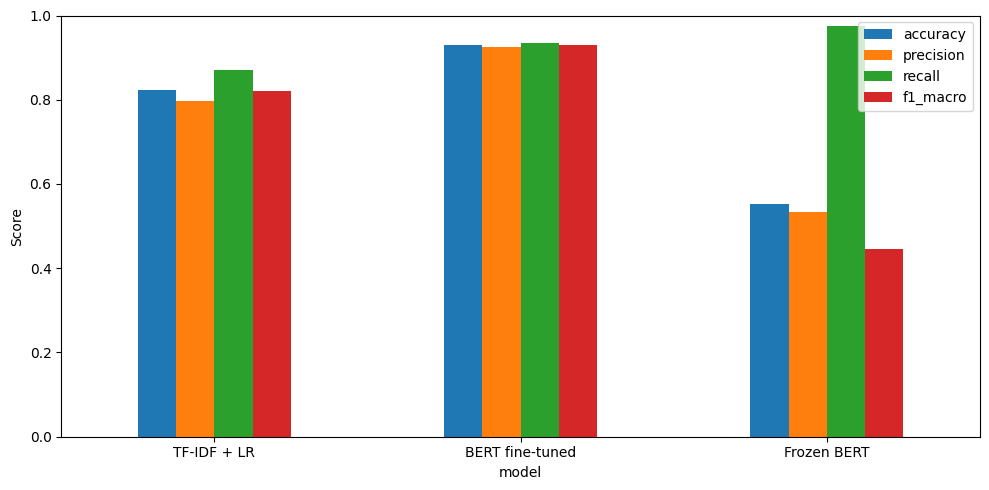

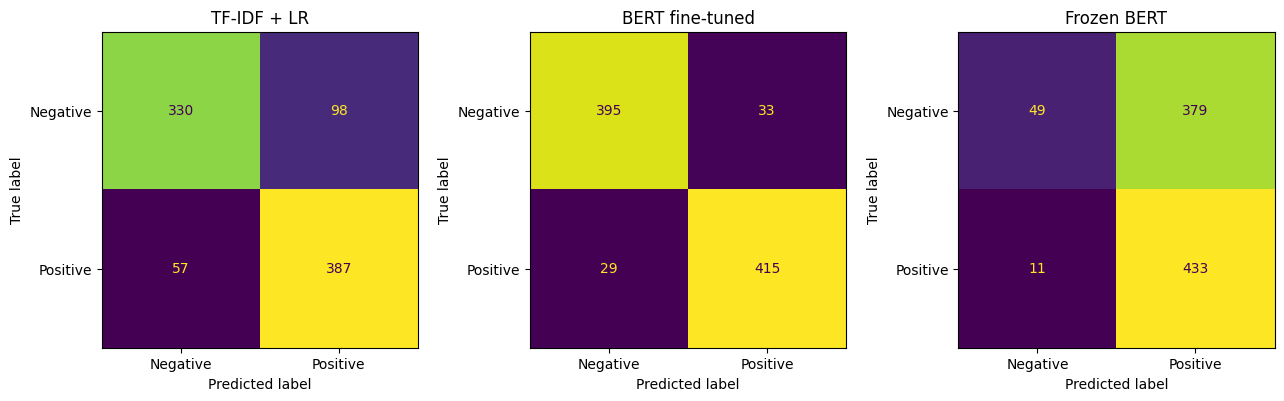

In [1]:
import zipfile, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

specs = [('baseline_artifacts','TF-IDF + LR','baseline_pred','baseline_prob_positive'),
         ('bert_artifacts','BERT fine-tuned','bert_pred','bert_prob_positive'),
         ('frozen_bert_artifacts','Frozen BERT','frozen_pred','frozen_prob_positive')]
# Accepte les archives une par une, ou plusieurs à la fois.
from google.colab import files
import re

for name, *_ in specs:
    target = Path(name + '.zip')
    while not target.exists():
        print('Sélectionner :', target.name, flush=True)
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError(f'Téléversement annulé : {target.name}. Relancer cette cellule pour reprendre.')
        for filename, content in uploaded.items():
            # Colab peut ajouter (1), (2), etc. aux noms déjà téléchargés.
            clean = re.sub(r' \(\d+\)(?=\.zip$)', '', Path(filename).name)
            expected = {item[0]+'.zip' for item in specs}
            if clean in expected:
                Path(clean).write_bytes(content)
        if not target.exists():
            print('Archive attendue non trouvée. Sélectionner exactement', target.name)
    with zipfile.ZipFile(target) as z:
        if 'predictions.csv' not in z.namelist():
            raise ValueError(f'{target.name} ne contient pas predictions.csv. Vérifier le fichier.')
    print('OK :', target.name)
print('Les trois archives sont disponibles. Comparaison en cours.')
def read_archive(name,filename):
    with zipfile.ZipFile(name+'.zip') as z:
        return pd.read_csv(io.BytesIO(z.read(filename)))
merged=None
metric_rows=[]
for name,label,pred,prob in specs:
    frame=read_archive(name,'predictions.csv')
    assert frame.idx.is_unique and len(frame)==872
    assert frame.label.isin([0,1]).all() and frame[pred].isin([0,1]).all()
    frame=frame[['idx','sentence','label',pred,prob]].sort_values('idx').reset_index(drop=True)
    if merged is None:
        merged=frame
    else:
        assert merged[['idx','sentence','label']].equals(frame[['idx','sentence','label']]), 'Archives incompatibles'
        merged=merged.merge(frame[['idx',pred,prob]],on='idx',validate='one_to_one')
    y=frame.label; p=frame[pred]
    tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    metric_rows.append(dict(model=label,accuracy=accuracy_score(y,p),precision=precision_score(y,p,zero_division=0),recall=recall_score(y,p,zero_division=0),f1=f1_score(y,p,zero_division=0),f1_macro=f1_score(y,p,average='macro'),errors=fp+fn,fpr=fp/(fp+tn),fnr=fn/(fn+tp)))
comparison=pd.DataFrame(metric_rows)
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(10,5))
comparison.set_index('model')[['accuracy','precision','recall','f1_macro']].plot.bar(ax=ax,rot=0)
ax.set_ylim(0,1);ax.set_ylabel('Score');plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(_,label,pred,_) in zip(axes,specs):
    ConfusionMatrixDisplay.from_predictions(merged.label,merged[pred],labels=[0,1],display_labels=['Negative','Positive'],colorbar=False,ax=ax)
    ax.set_title(label)
plt.tight_layout();plt.show()

,model,length_group,n,accuracy,f1_macro
0,TF-IDF + LR,1-10,152,0.8684,0.8678
1,BERT fine-tuned,1-10,152,0.9342,0.9335
2,Frozen BERT,1-10,152,0.4803,0.3725
3,TF-IDF + LR,11-20,340,0.8412,0.8401
4,BERT fine-tuned,11-20,340,0.9206,0.9205
5,Frozen BERT,11-20,340,0.5529,0.4449
6,TF-IDF + LR,21+,380,0.7868,0.7846
7,BERT fine-tuned,21+,380,0.9342,0.9340
8,Frozen BERT,21+,380,0.5816,0.4753


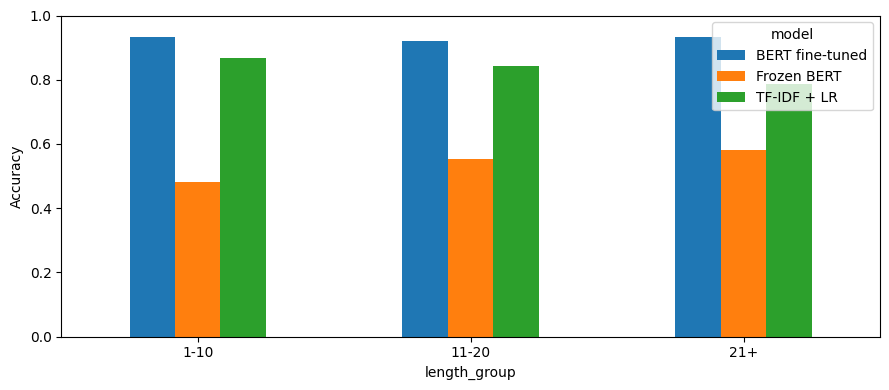

BERT correct,False,True
Baseline correcte,,
False,33,122
True,29,688


Erreurs baseline corrigées par BERT : 122
Erreurs BERT sur exemples réussis par baseline : 29
McNemar exact p (exploratoire): 9.023809939632868e-15


In [2]:
merged['word_count']=merged.sentence.str.split().str.len()
merged['length_group']=pd.cut(merged.word_count,[0,10,20,np.inf],labels=['1-10','11-20','21+'])
length_comparison=pd.DataFrame([dict(model=label,length_group=str(group),n=len(frame),accuracy=accuracy_score(frame.label,frame[pred]),f1_macro=f1_score(frame.label,frame[pred],labels=[0,1],average='macro',zero_division=0)) for group,frame in merged.groupby('length_group',observed=True) for _,label,pred,_ in specs])
display(length_comparison.round(4))
ax=length_comparison.pivot(index='length_group',columns='model',values='accuracy').reindex(['1-10','11-20','21+']).plot.bar(figsize=(9,4),rot=0)
ax.set_ylim(0,1);ax.set_ylabel('Accuracy');plt.tight_layout();plt.show()
a=merged.baseline_pred.eq(merged.label)
b=merged.bert_pred.eq(merged.label)
display(pd.crosstab(a,b,rownames=['Baseline correcte'],colnames=['BERT correct']))
from scipy.stats import binomtest
n01=int((~a & b).sum());n10=int((a & ~b).sum())
print('Erreurs baseline corrigées par BERT :',n01)
print('Erreurs BERT sur exemples réussis par baseline :',n10)
print('McNemar exact p (exploratoire):',binomtest(n01,n01+n10,.5).pvalue if n01+n10 else 1.)

## 11. Analyse qualitative de dix erreurs réelles

Échantillon reproductible de cinq faux positifs et cinq faux négatifs de BERT, choisi par seed et non selon une hypothèse sémantique. Les catégories doivent être attribuées manuellement après lecture des phrases complètes : négation, contraste, ironie, ambiguïté, connaissance externe, sentiment implicite, autre. Ne pas forcer une catégorie si la cause est incertaine. Comparer aussi les prédictions des deux autres modèles.

In [3]:
fp=merged[(merged.label==0)&(merged.bert_pred==1)]
fn=merged[(merged.label==1)&(merged.bert_pred==0)]
errors=pd.concat([fp.sample(min(5,len(fp)),random_state=42),fn.sample(min(5,len(fn)),random_state=42)])
errors=errors[['idx','sentence','label','baseline_pred','bert_pred','frozen_pred','bert_prob_positive']].copy()
errors['category']='À annoter'
errors['explanation']='À annoter'
with pd.option_context('display.max_colwidth',None,'display.max_columns',None):
    display(errors)
out=Path('final_reporting');out.mkdir(exist_ok=True)
comparison.to_csv(out/'comparison.csv',index=False)
length_comparison.to_csv(out/'length_comparison.csv',index=False)
merged.to_csv(out/'all_predictions.csv',index=False)
errors.to_csv(out/'error_analysis_to_annotate.csv',index=False)
print('Tableaux sauvegardés dans final_reporting.')

,idx,sentence,label,baseline_pred,bert_pred,frozen_pred,bert_prob_positive,category,explanation
832,832,manages to show life in all of its banality when the intention is quite the opposite .,0,1,1,1,0.941223,À annoter,À annoter
544,544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything but fun .",0,1,1,1,0.998774,À annoter,À annoter
764,764,"movie fans , get ready to take off ... the other direction .",0,0,1,1,0.981418,À annoter,À annoter
580,580,"it takes a certain kind of horror movie to qualify as ` worse than expected , ' but ghost ship somehow manages to do exactly that .",0,0,1,1,0.892281,À annoter,À annoter
183,183,"the lower your expectations , the more you 'll enjoy it .",0,1,1,1,0.997561,À annoter,À annoter
760,760,"writer/director joe carnahan 's grimy crime drama is a manual of precinct cliches , but it moves fast enough to cover its clunky dialogue and lapses in logic .",1,0,0,1,0.239305,À annoter,À annoter
509,509,a movie that successfully crushes a best selling novel into a timeframe that mandates that you avoid the godzilla sized soda .,1,1,0,1,0.271541,À annoter,À annoter
422,422,"it moves quickly , adroitly , and without fuss ; it does n't give you time to reflect on the inanity -- and the cold war datedness -- of its premise .",1,0,0,1,0.246261,À annoter,À annoter
667,667,"good film , but very glum .",1,1,0,1,0.343645,À annoter,À annoter
271,271,as unseemly as its title suggests .,1,0,0,1,0.006758,À annoter,À annoter


Tableaux sauvegardés dans final_reporting.


### Annotation qualitative des dix erreurs

Les annotations ci-dessous sont des hypothèses linguistiques fondées sur les phrases observées, et non des explications causales internes du modèle. Les labels officiels sont conservés, y compris lorsque le sentiment est ambigu.

In [4]:
annotations = {
832: ("Contraste implicite", "La banalité est présentée comme un échec contraire à l'intention du film."),
544: ("Concession et négation idiomatique", "L'éloge de Huppert est suivi de anything but fun, qui exclut une appréciation positive du film."),
764: ("Ironie", "L'invitation à décoller est détournée par the other direction, suggérant de fuir le film."),
580: ("Comparaison négative et ironie", "Worse than expected et exactly that expriment une déception malgré manages."),
183: ("Ambiguïté et éloge conditionnel", "Enjoy it est positif localement, mais l'exigence de faibles attentes suggère une critique mitigée. Le label négatif est discutable."),
760: ("Concession", "Les clichés et défauts sont compensés par le rythme rapide, ce qui soutient le label positif."),
509: ("Humour et sens figuré", "Successfully crushes indique une adaptation réussie ; la référence au soda est une plaisanterie sur la durée ou l'absence de pause."),
422: ("Concession implicite", "Le rythme et l'adresse sont valorisés malgré une prémisse jugée absurde et datée."),
667: ("Sentiment mixte", "Good film est un jugement favorable, mais very glum décrit une tonalité sombre."),
271: ("Ambiguïté pragmatique", "Unseemly est lexicalement négatif ; sans contexte, le label positif est difficile à justifier. Une appréciation de la provocation est possible.")
}
errors['category'] = errors['idx'].map(lambda i: annotations.get(int(i), ('À annoter','À annoter'))[0])
errors['explanation'] = errors['idx'].map(lambda i: annotations.get(int(i), ('À annoter','À annoter'))[1])
with pd.option_context('display.max_colwidth',None,'display.max_columns',None):
    display(errors)
errors.to_csv(out/'error_analysis.csv',index=False)

,idx,sentence,label,baseline_pred,bert_pred,frozen_pred,bert_prob_positive,category,explanation
832,832,manages to show life in all of its banality when the intention is quite the opposite .,0,1,1,1,0.941223,Contraste implicite,La banalité est présentée comme un échec contraire à l'intention du film.
544,544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything but fun .",0,1,1,1,0.998774,Concession et négation idiomatique,"L'éloge de Huppert est suivi de anything but fun, qui exclut une appréciation positive du film."
764,764,"movie fans , get ready to take off ... the other direction .",0,0,1,1,0.981418,Ironie,"L'invitation à décoller est détournée par the other direction, suggérant de fuir le film."
580,580,"it takes a certain kind of horror movie to qualify as ` worse than expected , ' but ghost ship somehow manages to do exactly that .",0,0,1,1,0.892281,Comparaison négative et ironie,Worse than expected et exactly that expriment une déception malgré manages.
183,183,"the lower your expectations , the more you 'll enjoy it .",0,1,1,1,0.997561,Ambiguïté et éloge conditionnel,"Enjoy it est positif localement, mais l'exigence de faibles attentes suggère une critique mitigée. Le label négatif est discutable."
760,760,"writer/director joe carnahan 's grimy crime drama is a manual of precinct cliches , but it moves fast enough to cover its clunky dialogue and lapses in logic .",1,0,0,1,0.239305,Concession,"Les clichés et défauts sont compensés par le rythme rapide, ce qui soutient le label positif."
509,509,a movie that successfully crushes a best selling novel into a timeframe that mandates that you avoid the godzilla sized soda .,1,1,0,1,0.271541,Humour et sens figuré,Successfully crushes indique une adaptation réussie ; la référence au soda est une plaisanterie sur la durée ou l'absence de pause.
422,422,"it moves quickly , adroitly , and without fuss ; it does n't give you time to reflect on the inanity -- and the cold war datedness -- of its premise .",1,0,0,1,0.246261,Concession implicite,Le rythme et l'adresse sont valorisés malgré une prémisse jugée absurde et datée.
667,667,"good film , but very glum .",1,1,0,1,0.343645,Sentiment mixte,"Good film est un jugement favorable, mais very glum décrit une tonalité sombre."
271,271,as unseemly as its title suggests .,1,0,0,1,0.006758,Ambiguïté pragmatique,"Unseemly est lexicalement négatif ; sans contexte, le label positif est difficile à justifier. Une appréciation de la provocation est possible."


## 12. Conclusion expérimentale

Sur 872 observations de validation officielle, TF-IDF + LR L2 C=5 atteint 82,22 % d'accuracy, BERT fine-tuné 92,89 % et Frozen BERT 55,28 %. Le fine-tuning réduit les erreurs de 155 à 62 (60 % de réduction nette), corrige 122 erreurs de la baseline et en introduit 29 sur des exemples auparavant réussis. Les 33 erreurs communes restent difficiles. Le test exact de McNemar donne p=9,02380993632868e-15, sous ses hypothèses ; l'analyse est exploratoire et limitée à cette partition. Sur les phrases de 21 mots et plus, l'accuracy progresse de 78,68 % à 93,42 %. Le gap F1 macro diminue de 15,64 à 5,21 points. La hausse de la loss de validation à l'époque 2 suggère un début de surapprentissage. Frozen BERT sous-apprend avec les hyperparamètres communs ; une optimisation spécifique pourrait améliorer ce résultat. Les annotations d'erreurs sont des interprétations plausibles, pas des preuves causales. Limites : une seule seed, validation déjà consultée, test officiel non étiqueté, comparaison de temps CPU/GPU non contrôlée. L'objectif d'environ 92 % est atteint.

In [5]:
import shutil
shutil.make_archive('final_reporting','zip',out)
from google.colab import files
files.download('final_reporting.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>